In [1]:
import os, json, time, random, platform
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.nn.functional as F
import torchvision
from torch.utils.data import ConcatDataset, Subset, DataLoader
from torchvision import models, transforms
from torchvision.datasets import OxfordIIITPet
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, f1_score, classification_report, ConfusionMatrixDisplay
from tqdm.auto import tqdm

device = "cuda" if torch.cuda.is_available() else "cpu"
print(f"Device: {device} | torch {torch.__version__} | torchvision {torchvision.__version__}")

Device: cuda | torch 2.14.0+cu132 | torchvision 0.29.0+cu132


c:\Users\Britod\.conda\envs\deep_learning\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [2]:
# Konfigurasi eksperimen (protokol seragam untuk semua kondisi)
DATA_ROOT = "./"
SEED = 42
BATCH_SIZE = 32
MAX_EPOCHS = 50
PATIENCE = 5
WEIGHT_DECAY = 1e-2
NUM_WORKERS = 2
CLASSES = ["Abyssinian", "Bengal", "Birman", "Persian", "Siamese",          # kucing
           "Beagle", "Boxer", "Chihuahua", "Pug", "Samoyed"]               # anjing
NUM_CLASSES = len(CLASSES)
MEAN, STD = [0.485, 0.456, 0.406], [0.229, 0.224, 0.225]

for d in ("logs", "checkpoints", "figures"):
    os.makedirs(d, exist_ok=True)

def seed_everything(seed=SEED):
    # Seed PyTorch, NumPy, dan Python built-in; dipanggil ulang di awal setiap eksperimen
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False

seed_everything()

# Warna plot: train = biru, validation = oranye (val juga garis putus-putus)
C_TRAIN, C_VAL = "#2a78d6", "#eb6834"
plt.rcParams.update({"axes.grid": True, "grid.alpha": 0.3, "axes.spines.top": False, "axes.spines.right": False})

## 1. Dataset & Stratified Split

In [3]:
# Augmentasi hanya untuk data latih; validasi/uji selalu deterministik
aug_transforms = transforms.Compose([
    transforms.Resize(256),
    transforms.RandomResizedCrop(224, scale=(0.8, 1.0)),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.RandomRotation(degrees=15),
    transforms.ColorJitter(brightness=0.2, contrast=0.2),
    transforms.ToTensor(),
    transforms.Normalize(MEAN, STD),
])
eval_transforms = transforms.Compose([   # juga dipakai sebagai train transform "tanpa augmentasi" (B4)
    transforms.Resize(256),
    transforms.CenterCrop(224),
    transforms.ToTensor(),
    transforms.Normalize(MEAN, STD),
])

In [4]:
all_classes = OxfordIIITPet(root=DATA_ROOT, split="trainval", download=True).classes
remap = {all_classes.index(c): i for i, c in enumerate(CLASSES)}  # id 37 kelas -> 0..9

def load_pool(transform):
    # Gabungkan split resmi trainval + test, lalu dibagi ulang 70/15/15
    return ConcatDataset([
        OxfordIIITPet(root=DATA_ROOT, split=s, transform=transform, target_transform=remap.get, download=True)
        for s in ("trainval", "test")
    ])

pools = {"aug": load_pool(aug_transforms), "eval": load_pool(eval_transforms)}
all_labels = np.array([l for ds in pools["eval"].datasets for l in ds._labels])
all_paths = [p for ds in pools["eval"].datasets for p in ds._images]
idx = np.where(np.isin(all_labels, list(remap)))[0]

train_idx, rest_idx = train_test_split(idx, test_size=0.30, stratify=all_labels[idx], random_state=SEED)
val_idx, test_idx = train_test_split(rest_idx, test_size=0.50, stratify=all_labels[rest_idx], random_state=SEED)
assert not (set(train_idx) & set(val_idx) or set(train_idx) & set(test_idx) or set(val_idx) & set(test_idx)), "data leakage"

split_counts = pd.DataFrame(
    {name: np.bincount([remap[l] for l in all_labels[s]], minlength=NUM_CLASSES)
     for name, s in [("train", train_idx), ("val", val_idx), ("test", test_idx)]},
    index=CLASSES)
split_counts.loc["TOTAL"] = split_counts.sum()
split_counts

,train,val,test
Abyssinian,139,29,30
Bengal,140,30,30
Birman,140,30,30
Persian,140,30,30
Siamese,139,30,30
Beagle,140,30,30
Boxer,139,30,30
Chihuahua,140,30,30
Pug,140,30,30
Samoyed,140,30,30


In [5]:
def make_loader(pool, indices, shuffle=False):
    # Generator ber-seed -> urutan shuffle identik di setiap kondisi eksperimen
    return DataLoader(Subset(pools[pool], indices), BATCH_SIZE, shuffle=shuffle, num_workers=NUM_WORKERS,
                      generator=torch.Generator().manual_seed(SEED) if shuffle else None)

val_loader = make_loader("eval", val_idx)
test_loader = make_loader("eval", test_idx)
train_eval_loader = make_loader("eval", train_idx)  # data latih tanpa augmentasi, untuk mengukur generalization gap

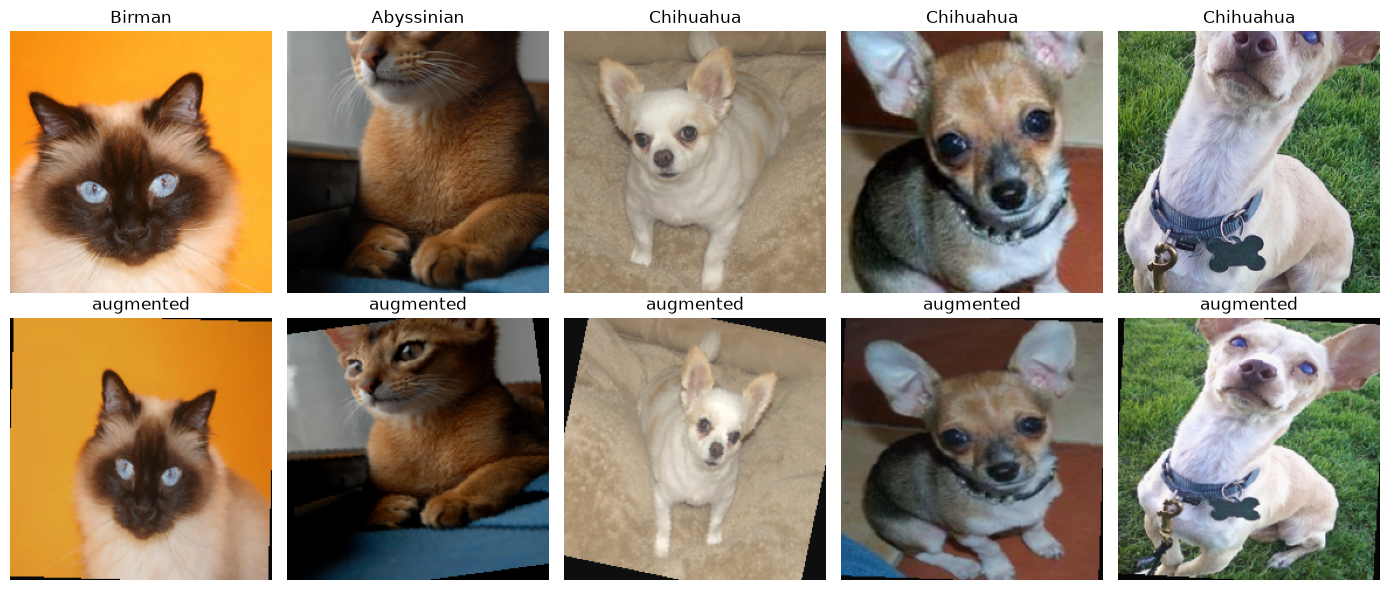

In [6]:
# Contoh citra latih: asli (eval transform) vs. teraugmentasi
def denorm(x):
    return (x.permute(1, 2, 0) * torch.tensor(STD) + torch.tensor(MEAN)).clamp(0, 1).numpy()

fig, axes = plt.subplots(2, 5, figsize=(14, 6))
for j, i in enumerate(train_idx[:5]):
    axes[0, j].imshow(denorm(pools["eval"][i][0])); axes[0, j].set_title(CLASSES[remap[all_labels[i]]])
    axes[1, j].imshow(denorm(pools["aug"][i][0])); axes[1, j].set_title("augmented")
for ax in axes.flat:
    ax.axis("off")
plt.tight_layout(); plt.show()

## 2. Model Builder (B1 / B2 / B3 / B5)

In [7]:
def count_params(model):
    trainable = sum(p.numel() for p in model.parameters() if p.requires_grad)
    return trainable, sum(p.numel() for p in model.parameters())

def build_model(arch="resnet18", mode="finetune"):
    """mode: 'scratch' (B1), 'feature' (B2), 'finetune' (B3/B4/B5). Return (model, param_groups)."""
    pretrained = mode != "scratch"
    if arch == "resnet18":
        model = models.resnet18(weights=models.ResNet18_Weights.IMAGENET1K_V1 if pretrained else None)
        model.fc = nn.Linear(model.fc.in_features, NUM_CLASSES)
        head, last_block = model.fc, model.layer4
    elif arch == "efficientnet_b0":
        model = models.efficientnet_b0(weights=models.EfficientNet_B0_Weights.IMAGENET1K_V1 if pretrained else None)
        model.classifier[-1] = nn.Linear(model.classifier[-1].in_features, NUM_CLASSES)
        head, last_block = model.classifier, model.features[-2:]   # stage MBConv terakhir + conv 1x1 akhir
    elif arch == "mobilenet_v3_small":
        model = models.mobilenet_v3_small(weights=models.MobileNet_V3_Small_Weights.IMAGENET1K_V1 if pretrained else None)
        model.classifier[-1] = nn.Linear(model.classifier[-1].in_features, NUM_CLASSES)
        head, last_block = model.classifier, model.features[-2:]
    else:
        raise ValueError(arch)

    if mode == "scratch":
        return model, [{"name": "all", "params": list(model.parameters()), "lr": 1e-3}]

    for p in model.parameters():
        p.requires_grad = False
    for p in head.parameters():
        p.requires_grad = True
    groups = [{"name": "head", "params": list(head.parameters()), "lr": 1e-3}]
    if mode == "finetune":
        for p in last_block.parameters():
            p.requires_grad = True
        groups.insert(0, {"name": "last_block", "params": list(last_block.parameters()), "lr": 1e-4})
    return model, groups

# Verifikasi jumlah trainable parameters sebelum optimizer dibentuk
for mode in ("scratch", "feature", "finetune"):
    t, total = count_params(build_model("resnet18", mode)[0])
    print(f"resnet18 {mode:9s}: trainable {t:>11,} / {total:,}")
assert count_params(build_model("resnet18", "feature")[0])[0] == 5130  # 512*10 + 10 (hanya fc)

resnet18 scratch  : trainable  11,181,642 / 11,181,642
resnet18 feature  : trainable       5,130 / 11,181,642
resnet18 finetune : trainable   8,398,858 / 11,181,642


## 3. Training Loop, Early Stopping & Logging

In [8]:
criterion = nn.CrossEntropyLoss()

def freeze_frozen_bn(model):
    # requires_grad=False tidak menghentikan update running mean/var BatchNorm saat model.train().
    # BN yang parameternya beku dipaksa eval agar statistik ImageNet benar-benar ikut "dibekukan".
    for m in model.modules():
        if isinstance(m, nn.modules.batchnorm._BatchNorm) and m.weight is not None and not m.weight.requires_grad:
            m.eval()

@torch.no_grad()
def evaluate(model, loader):
    model.eval()
    total_loss, probs, labels = 0.0, [], []
    for x, y in loader:
        out = model(x.to(device))
        total_loss += criterion(out, y.to(device)).item() * len(y)
        probs.append(out.softmax(1).cpu())
        labels.append(y)
    probs, labels = torch.cat(probs), torch.cat(labels)
    return total_loss / len(labels), (probs.argmax(1) == labels).float().mean().item(), probs, labels

@torch.no_grad()
def measure_latency(model, runs=50):
    # Latensi inferensi murni (batch 1), tanpa dataloading
    model.eval()
    x = torch.randn(1, 3, 224, 224, device=device)
    for _ in range(10):
        model(x)
    if device == "cuda": torch.cuda.synchronize()
    t0 = time.perf_counter()
    for _ in range(runs):
        model(x)
    if device == "cuda": torch.cuda.synchronize()
    return (time.perf_counter() - t0) / runs * 1000

In [9]:
def run_experiment(name, arch="resnet18", mode="finetune", augment=True):
    seed_everything()
    model, groups = build_model(arch, mode)
    model.to(device)
    trainable, total = count_params(model)
    lr_str = ", ".join(f"{g['name']}={g['lr']:g}" for g in groups)
    print(f"[{name}] {arch} | mode={mode} | augment={augment} | trainable {trainable:,}/{total:,} | lr: {lr_str}")

    optimizer = torch.optim.AdamW(groups, weight_decay=WEIGHT_DECAY)
    train_loader = make_loader("aug" if augment else "eval", train_idx, shuffle=True)
    ckpt = f"checkpoints/{name}.pt"

    history, best_vloss, best_epoch, bad_epochs = [], float("inf"), 0, 0
    start = time.perf_counter()
    for epoch in range(1, MAX_EPOCHS + 1):
        model.train()
        freeze_frozen_bn(model)
        run_loss, correct, n = 0.0, 0, 0
        for x, y in tqdm(train_loader, desc=f"{name} ep{epoch}", leave=False):
            x, y = x.to(device), y.to(device)
            optimizer.zero_grad()
            out = model(x)
            loss = criterion(out, y)
            loss.backward()
            optimizer.step()
            run_loss += loss.item() * len(y)
            correct += (out.argmax(1) == y).sum().item()
            n += len(y)
        val_loss, val_acc, _, _ = evaluate(model, val_loader)
        history.append({"experiment": name, "epoch": epoch, "train_loss": run_loss / n, "train_acc": correct / n,
                        "val_loss": val_loss, "val_acc": val_acc, "elapsed_s": time.perf_counter() - start})
        print(f"  ep {epoch:2d} | train loss {run_loss / n:.4f} acc {correct / n:.4f} | val loss {val_loss:.4f} acc {val_acc:.4f}")

        # Early stopping memonitor validation loss
        if val_loss < best_vloss:
            best_vloss, best_epoch, bad_epochs = val_loss, epoch, 0
            torch.save(model.state_dict(), ckpt)
        else:
            bad_epochs += 1
            if bad_epochs >= PATIENCE:
                print(f"  early stopping at epoch {epoch} (best epoch {best_epoch})")
                break
    train_time = time.perf_counter() - start

    # Evaluasi akhir dengan bobot terbaik; test set hanya disentuh di sini
    model.load_state_dict(torch.load(ckpt, map_location=device))
    val_loss, val_acc, _, _ = evaluate(model, val_loader)
    _, train_acc, _, _ = evaluate(model, train_eval_loader)
    _, test_acc, probs, labels = evaluate(model, test_loader)
    summary = {
        "experiment": name, "arch": arch, "mode": mode, "augment": augment,
        "trainable_params": trainable, "total_params": total, "lr_per_group": lr_str,
        "epochs_run": len(history), "best_epoch": best_epoch, "train_time_s": round(train_time, 1),
        "train_acc": train_acc, "val_loss": val_loss, "val_acc": val_acc, "gap_train_val": train_acc - val_acc,
        "test_acc": test_acc, "test_macro_f1": f1_score(labels, probs.argmax(1), average="macro"),
        "latency_ms": round(measure_latency(model), 2),
    }
    print(f"  -> val acc {val_acc:.4f} | test acc {test_acc:.4f} | test macro F1 {summary['test_macro_f1']:.4f} | {train_time:.0f}s")
    return {"history": history, "summary": summary}

In [10]:
results = {}
CONFIG = {
    "seed": SEED, "batch_size": BATCH_SIZE, "max_epochs": MAX_EPOCHS, "patience": PATIENCE,
    "optimizer": "AdamW", "weight_decay": WEIGHT_DECAY, "loss": "CrossEntropyLoss", "input_size": 224,
    "classes": CLASSES, "split_sizes": {"train": len(train_idx), "val": len(val_idx), "test": len(test_idx)},
    "device": torch.cuda.get_device_name(0) if device == "cuda" else "cpu",
    "torch": torch.__version__, "torchvision": torchvision.__version__, "python": platform.python_version(),
}

def save_logs():
    history = [h for r in results.values() for h in r["history"]]
    summary = [r["summary"] for r in results.values()]
    pd.DataFrame(history).to_csv("logs/history.csv", index=False)
    pd.DataFrame(summary).to_csv("logs/summary.csv", index=False)
    with open("logs/metrics.json", "w") as f:
        json.dump({"config": CONFIG, "summary": summary, "history": history}, f, indent=2)

def run(name, **kw):
    results[name] = run_experiment(name, **kw)
    save_logs()  # log disimpan setiap selesai satu kondisi (aman jika runtime Colab terputus)

## 4. Matriks Eksperimen
### B1 — Baseline from Scratch

In [11]:
run("B1_scratch", mode="scratch")

[B1_scratch] resnet18 | mode=scratch | augment=True | trainable 11,181,642/11,181,642 | lr: all=0.001


  ep  1 | train loss 2.3303 acc 0.1682 | val loss 2.0869 acc 0.2676


  ep  2 | train loss 2.0997 acc 0.2405 | val loss 2.1720 acc 0.2809


  ep  3 | train loss 1.9919 acc 0.2684 | val loss 2.3666 acc 0.2174


  ep  4 | train loss 1.8962 acc 0.3157 | val loss 2.0039 acc 0.2876


...

  ep 16 | train loss 1.0386 acc 0.6285 | val loss 2.2354 acc 0.4381


  ep 17 | train loss 0.9579 acc 0.6492 | val loss 1.4588 acc 0.5117


  ep 18 | train loss 0.9445 acc 0.6657 | val loss 1.5627 acc 0.5050


  ep 19 | train loss 0.9139 acc 0.6700 | val loss 1.8938 acc 0.4582


  ep 20 | train loss 0.8527 acc 0.6965 | val loss 1.5782 acc 0.4916
  early stopping at epoch 20 (best epoch 15)
  -> val acc 0.5251 | test acc 0.5400 | test macro F1 0.5199 | 441s


### B2 — Feature Extraction

In [12]:
run("B2_feature", mode="feature")

[B2_feature] resnet18 | mode=feature | augment=True | trainable 5,130/11,181,642 | lr: head=0.001


  ep  1 | train loss 1.2724 acc 0.6428 | val loss 0.5257 acc 0.9064


  ep  2 | train loss 0.4295 acc 0.9141 | val loss 0.3205 acc 0.9130


  ep  3 | train loss 0.2846 acc 0.9506 | val loss 0.2416 acc 0.9431


  ep  4 | train loss 0.2371 acc 0.9456 | val loss 0.2030 acc 0.9431


...

  ep 26 | train loss 0.0676 acc 0.9814 | val loss 0.1269 acc 0.9498


  ep 27 | train loss 0.0568 acc 0.9857 | val loss 0.1226 acc 0.9532


  ep 28 | train loss 0.0555 acc 0.9885 | val loss 0.1207 acc 0.9666


  ep 29 | train loss 0.0609 acc 0.9821 | val loss 0.1384 acc 0.9498


  ep 30 | train loss 0.0505 acc 0.9907 | val loss 0.1238 acc 0.9498
  early stopping at epoch 30 (best epoch 25)
  -> val acc 0.9465 | test acc 0.9533 | test macro F1 0.9534 | 665s


### B3 — Progressive Fine-Tuning (differential learning rate)

In [13]:
run("B3_finetune", mode="finetune")

[B3_finetune] resnet18 | mode=finetune | augment=True | trainable 8,398,858/11,181,642 | lr: last_block=0.0001, head=0.001


  ep  1 | train loss 0.7210 acc 0.7853 | val loss 0.1700 acc 0.9264


  ep  2 | train loss 0.1452 acc 0.9599 | val loss 0.1556 acc 0.9365


  ep  3 | train loss 0.0777 acc 0.9850 | val loss 0.1204 acc 0.9632


  ep  4 | train loss 0.0526 acc 0.9893 | val loss 0.1158 acc 0.9632


...

  ep  8 | train loss 0.0268 acc 0.9936 | val loss 0.1080 acc 0.9599


  ep  9 | train loss 0.0178 acc 0.9950 | val loss 0.1361 acc 0.9565


  ep 10 | train loss 0.0140 acc 0.9957 | val loss 0.1320 acc 0.9565


  ep 11 | train loss 0.0145 acc 0.9950 | val loss 0.1620 acc 0.9532


  ep 12 | train loss 0.0179 acc 0.9950 | val loss 0.1303 acc 0.9431
  early stopping at epoch 12 (best epoch 7)
  -> val acc 0.9565 | test acc 0.9567 | test macro F1 0.9567 | 269s


### B4 — Uji Kontrol Data Augmentation (pada B3)
Skenario *dengan* augmentasi = B3 di atas; di sini dijalankan skenario *tanpa* augmentasi (hanya Resize/CenterCrop + Normalisasi).

In [14]:
run("B4_finetune_noaug", mode="finetune", augment=False)

[B4_finetune_noaug] resnet18 | mode=finetune | augment=False | trainable 8,398,858/11,181,642 | lr: last_block=0.0001, head=0.001


  ep  1 | train loss 0.6184 acc 0.8232 | val loss 0.1568 acc 0.9431


  ep  2 | train loss 0.0574 acc 0.9914 | val loss 0.1206 acc 0.9599


  ep  3 | train loss 0.0222 acc 1.0000 | val loss 0.1142 acc 0.9599


  ep  4 | train loss 0.0120 acc 1.0000 | val loss 0.0966 acc 0.9699


...

  ep 11 | train loss 0.0017 acc 1.0000 | val loss 0.1011 acc 0.9666


  ep 12 | train loss 0.0016 acc 1.0000 | val loss 0.0959 acc 0.9666


  ep 13 | train loss 0.0014 acc 1.0000 | val loss 0.1002 acc 0.9666


  ep 14 | train loss 0.0010 acc 1.0000 | val loss 0.0988 acc 0.9666


  ep 15 | train loss 0.0008 acc 1.0000 | val loss 0.1029 acc 0.9666
  early stopping at epoch 15 (best epoch 10)
  -> val acc 0.9699 | test acc 0.9633 | test macro F1 0.9634 | 323s


### B5 — Arsitektur Pembanding (bonus)
Konfigurasi terbaik dipilih berdasarkan **validasi** (bukan test) dari B2/B3/B4, lalu dijalankan pada EfficientNet-B0 dan MobileNetV3-Small.

In [15]:
cand = pd.DataFrame([results[k]["summary"] for k in ("B2_feature", "B3_finetune", "B4_finetune_noaug")])
best_cfg = cand.sort_values(["val_acc", "val_loss"], ascending=[False, True]).iloc[0]
print(f"Konfigurasi terbaik: {best_cfg['experiment']} (mode={best_cfg['mode']}, augment={best_cfg['augment']})")

for arch in ("efficientnet_b0", "mobilenet_v3_small"):
    run(f"B5_{arch}", arch=arch, mode=best_cfg["mode"], augment=bool(best_cfg["augment"]))

Konfigurasi terbaik: B4_finetune_noaug (mode=finetune, augment=False)
[B5_efficientnet_b0] efficientnet_b0 | mode=finetune | augment=False | trainable 1,142,202/4,020,358 | lr: last_block=0.0001, head=0.001


  ep  1 | train loss 0.9586 acc 0.8031 | val loss 0.1990 acc 0.9532


  ep  2 | train loss 0.1599 acc 0.9685 | val loss 0.1249 acc 0.9565


  ep  3 | train loss 0.1050 acc 0.9764 | val loss 0.0962 acc 0.9799


  ep  4 | train loss 0.0722 acc 0.9814 | val loss 0.0792 acc 0.9866


...

  ep  4 | train loss 0.0589 acc 0.9864 | val loss 0.1721 acc 0.9431


  ep  5 | train loss 0.0366 acc 0.9921 | val loss 0.1740 acc 0.9264


  ep  6 | train loss 0.0549 acc 0.9828 | val loss 0.2624 acc 0.9231


  ep  7 | train loss 0.0399 acc 0.9914 | val loss 0.1821 acc 0.9398


  ep  8 | train loss 0.0205 acc 0.9936 | val loss 0.1968 acc 0.9465
  early stopping at epoch 8 (best epoch 3)
  -> val acc 0.9465 | test acc 0.9700 | test macro F1 0.9701 | 162s


## 5. C1 — Tabel Konsolidasi & Kurva Pembelajaran

In [16]:
summary_df = pd.DataFrame([r["summary"] for r in results.values()])
history_df = pd.DataFrame([h for r in results.values() for h in r["history"]])

summary_df[["experiment", "arch", "mode", "augment", "trainable_params", "lr_per_group", "best_epoch", "epochs_run",
            "train_time_s", "train_acc", "val_acc", "gap_train_val", "test_acc", "test_macro_f1", "latency_ms"]] \
    .style.format({"trainable_params": "{:,}", "train_acc": "{:.4f}", "val_acc": "{:.4f}", "gap_train_val": "{:+.4f}",
                   "test_acc": "{:.4f}", "test_macro_f1": "{:.4f}"}).hide(axis="index")

experiment,arch,mode,augment,trainable_params,lr_per_group,best_epoch,epochs_run,train_time_s,train_acc,val_acc,gap_train_val,test_acc,test_macro_f1,latency_ms
B1_scratch,resnet18,scratch,True,"11,181,642",all=0.001,15,20,440.900000,0.6206,0.5251,+0.0955,0.5400,0.5199,1.500000
B2_feature,resnet18,feature,True,"5,130",head=0.001,25,30,665.000000,0.9921,0.9465,+0.0456,0.9533,0.9534,1.250000
B3_finetune,resnet18,finetune,True,"8,398,858","last_block=0.0001, head=0.001",7,12,268.500000,0.9986,0.9565,+0.0420,0.9567,0.9567,1.440000
B4_finetune_noaug,resnet18,finetune,False,"8,398,858","last_block=0.0001, head=0.001",10,15,323.200000,1.0000,0.9699,+0.0301,0.9633,0.9634,1.360000
B5_efficientnet_b0,efficientnet_b0,finetune,False,"1,142,202","last_block=0.0001, head=0.001",7,12,261.400000,1.0000,0.9866,+0.0134,0.9767,0.9766,4.210000
B5_mobilenet_v3_small,mobilenet_v3_small,finetune,False,"951,642","last_block=0.0001, head=0.001",3,8,161.900000,0.9936,0.9465,+0.0471,0.9700,0.9701,2.700000


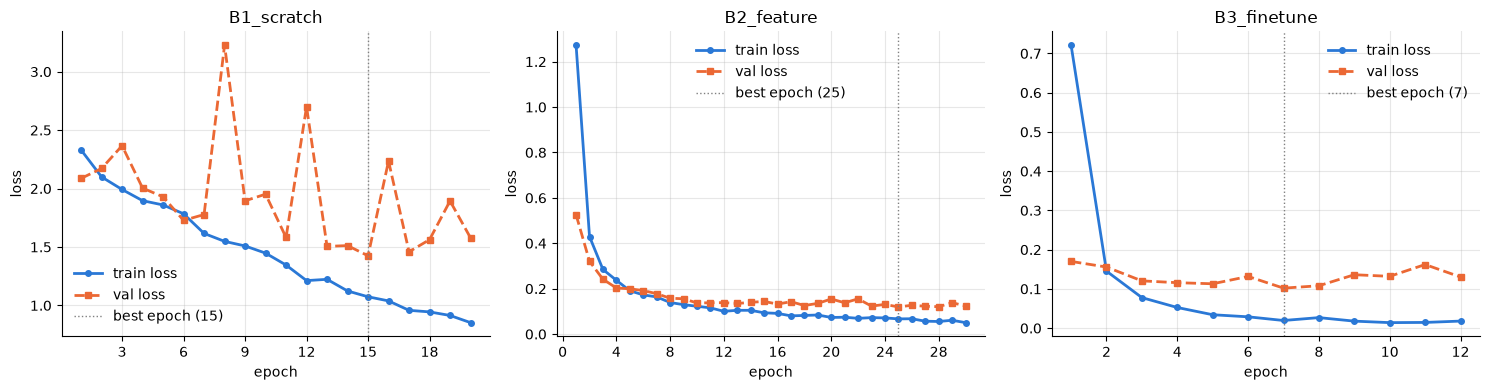

In [17]:
def plot_curves(names, metric, fname):
    fig, axes = plt.subplots(1, len(names), figsize=(5 * len(names), 4), sharey=(metric == "acc"))
    for ax, name in zip(np.atleast_1d(axes), names):
        h = history_df[history_df.experiment == name]
        best = results[name]["summary"]["best_epoch"]
        ax.plot(h.epoch, h[f"train_{metric}"], color=C_TRAIN, lw=2, marker="o", ms=4, label=f"train {metric}")
        ax.plot(h.epoch, h[f"val_{metric}"], color=C_VAL, lw=2, ls="--", marker="s", ms=4, label=f"val {metric}")
        ax.axvline(best, color="gray", lw=1, ls=":", label=f"best epoch ({best})")
        ax.set(title=name, xlabel="epoch", ylabel=metric)
        ax.xaxis.set_major_locator(plt.MaxNLocator(integer=True))
        ax.legend(frameon=False)
    plt.tight_layout()
    fig.savefig(f"figures/{fname}", dpi=150)
    plt.show()

plot_curves(["B1_scratch", "B2_feature", "B3_finetune"], "loss", "loss_curves_B1_B2_B3.png")

### B4 — Generalization gap: dengan vs. tanpa augmentasi

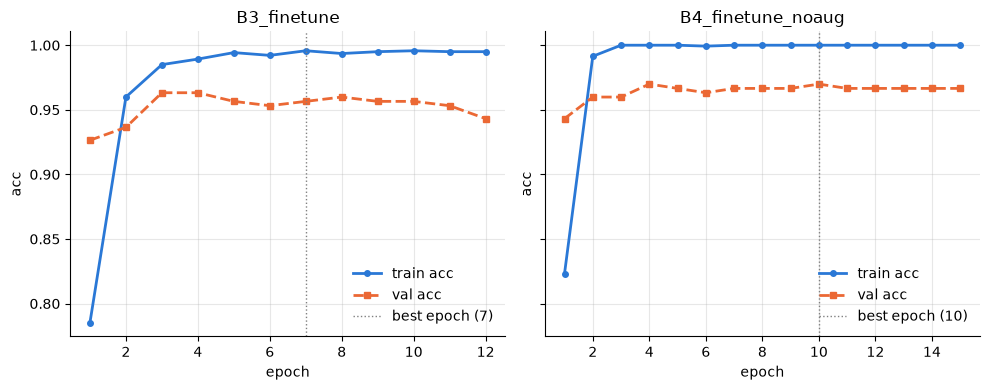

,experiment,augment,best_epoch,train_acc,val_acc,gap_train_val,test_macro_f1
2,B3_finetune,True,7,0.9986,0.9565,0.0420,0.9567
3,B4_finetune_noaug,False,10,1.0000,0.9699,0.0301,0.9634


In [18]:
plot_curves(["B3_finetune", "B4_finetune_noaug"], "acc", "acc_curves_B4.png")
summary_df[summary_df.experiment.isin(["B3_finetune", "B4_finetune_noaug"])][
    ["experiment", "augment", "best_epoch", "train_acc", "val_acc", "gap_train_val", "test_macro_f1"]].round(4)

### B5 — Trade-off efisiensi vs. performa

In [19]:
b5 = summary_df[summary_df.experiment.isin(["B3_finetune", "B4_finetune_noaug", "B5_efficientnet_b0", "B5_mobilenet_v3_small"])
                & (summary_df["mode"] == best_cfg["mode"]) & (summary_df["augment"] == best_cfg["augment"])]
b5[["experiment", "arch", "total_params", "trainable_params", "train_time_s", "latency_ms", "test_macro_f1"]].round(4)

,experiment,arch,total_params,trainable_params,train_time_s,latency_ms,test_macro_f1
3,B4_finetune_noaug,resnet18,11181642,8398858,323.2,1.36,0.9634
4,B5_efficientnet_b0,efficientnet_b0,4020358,1142202,261.4,4.21,0.9766
5,B5_mobilenet_v3_small,mobilenet_v3_small,1528106,951642,161.9,2.70,0.9701


## 6. C3 — Failure Analysis (model terbaik)
Model terbaik dipilih berdasarkan akurasi validasi (tie-break: validation loss).

Model terbaik: B5_efficientnet_b0 | test acc 0.9767 | test macro F1 0.9766

              precision    recall  f1-score   support

  Abyssinian     0.9375    1.0000    0.9677        30
      Bengal     1.0000    0.9333    0.9655        30
      Birman     0.9062    0.9667    0.9355        30
     Persian     1.0000    1.0000    1.0000        30
     Siamese     0.9643    0.9000    0.9310        30
      Beagle     1.0000    1.0000    1.0000        30
       Boxer     0.9677    1.0000    0.9836        30
   Chihuahua     1.0000    1.0000    1.0000        30
         Pug     1.0000    0.9667    0.9831        30
     Samoyed     1.0000    1.0000    1.0000        30

    accuracy                         0.9767       300
   macro avg     0.9776    0.9767    0.9766       300
weighted avg     0.9776    0.9767    0.9766       300



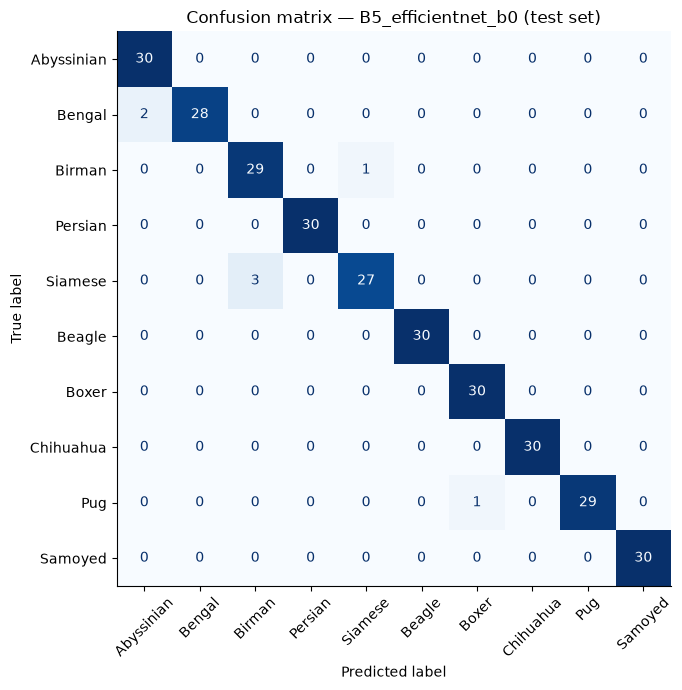

In [20]:
best_row = summary_df.sort_values(["val_acc", "val_loss"], ascending=[False, True]).iloc[0]
best_model, _ = build_model(best_row["arch"], best_row["mode"])
best_model.load_state_dict(torch.load(f"checkpoints/{best_row['experiment']}.pt", map_location=device))
best_model.to(device)
_, test_acc, probs, labels = evaluate(best_model, test_loader)
preds = probs.argmax(1)
print(f"Model terbaik: {best_row['experiment']} | test acc {test_acc:.4f} | "
      f"test macro F1 {f1_score(labels, preds, average='macro'):.4f}\n")
print(classification_report(labels, preds, target_names=CLASSES, digits=4))

fig, ax = plt.subplots(figsize=(8, 7))
ConfusionMatrixDisplay.from_predictions(labels, preds, display_labels=CLASSES, xticks_rotation=45, cmap="Blues",
                                        colorbar=False, ax=ax)
ax.grid(False); ax.set_title(f"Confusion matrix — {best_row['experiment']} (test set)")
plt.tight_layout(); fig.savefig("figures/confusion_matrix_best.png", dpi=150); plt.show()

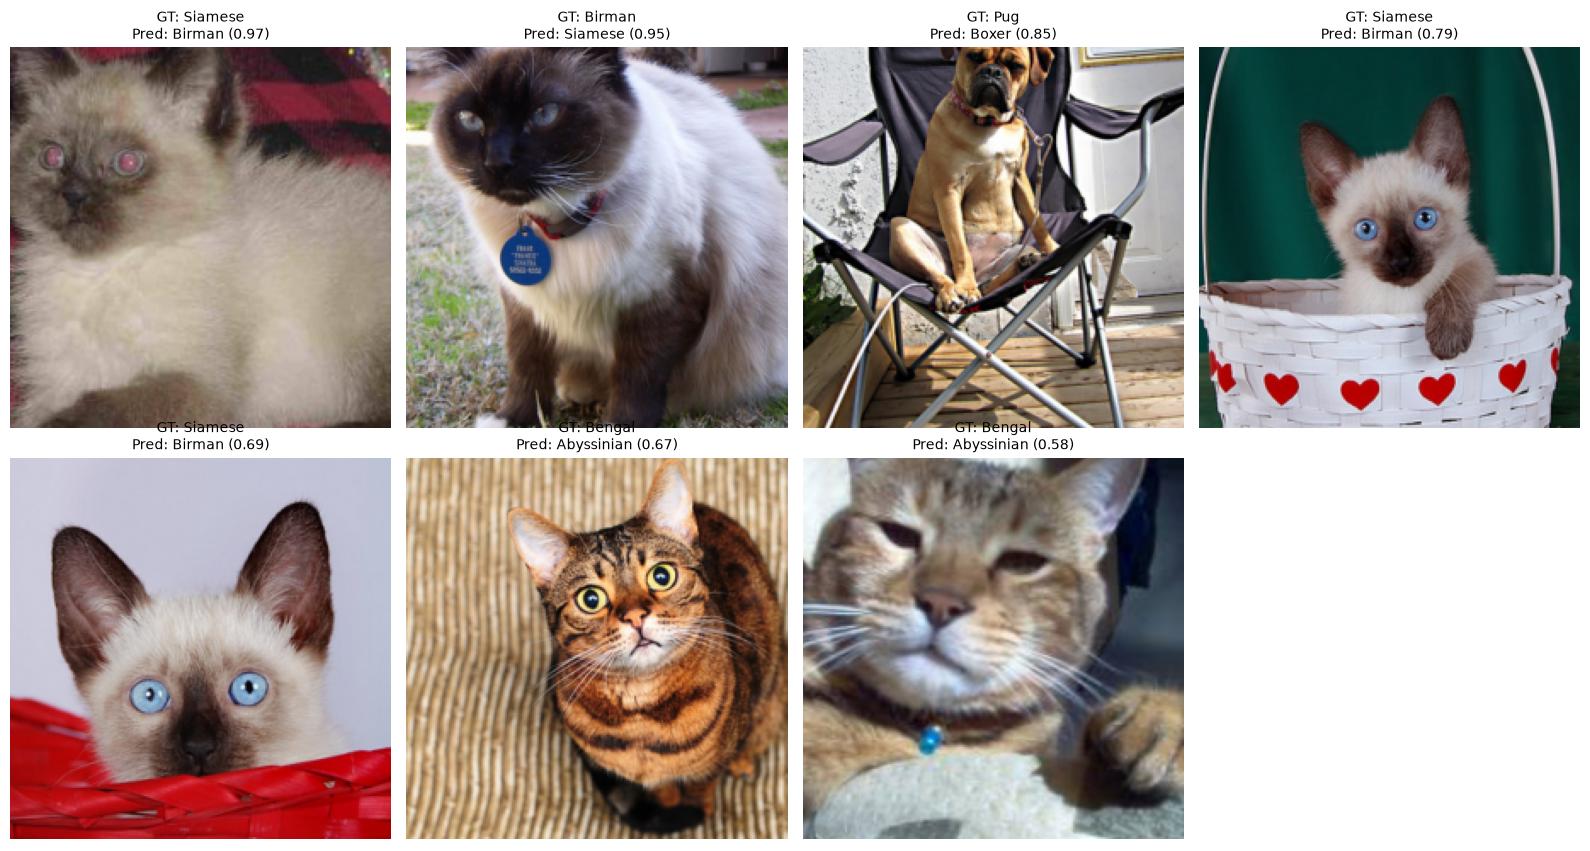

Total misklasifikasi: 7 / 300


,file,ground_truth,prediction,confidence,p(ground_truth),2nd_choice
0,Siamese_257.jpg,Siamese,Birman,0.9670,0.0256,Siamese
1,Birman_57.jpg,Birman,Siamese,0.9502,0.0495,Birman
2,pug_74.jpg,Pug,Boxer,0.8518,0.1431,Pug
3,Siamese_185.jpg,Siamese,Birman,0.7943,0.2050,Siamese
4,Siamese_183.jpg,Siamese,Birman,0.6908,0.3070,Siamese
5,Bengal_100.jpg,Bengal,Abyssinian,0.6725,0.3261,Bengal
6,Bengal_143.jpg,Bengal,Abyssinian,0.5783,0.4211,Bengal


In [ ]:
wrong = torch.where(preds != labels)[0]
wrong = wrong[probs[wrong].max(1).values.argsort(descending=True)][:8] 

rows = []
fig, axes = plt.subplots(2, 4, figsize=(16, 8.5))
for ax in axes.flat:
    ax.axis("off")
for ax, k in zip(axes.flat, wrong.tolist()):
    i = test_idx[k]
    top2 = probs[k].topk(2)
    ax.imshow(denorm(pools["eval"][i][0]))
    ax.set_title(f"GT: {CLASSES[labels[k]]}\nPred: {CLASSES[preds[k]]} ({top2.values[0]:.2f})", fontsize=10)
    rows.append({"file": os.path.basename(all_paths[i]), "ground_truth": CLASSES[labels[k]],
                 "prediction": CLASSES[preds[k]], "confidence": round(top2.values[0].item(), 4),
                 "p(ground_truth)": round(probs[k, labels[k]].item(), 4),
                 "2nd_choice": CLASSES[top2.indices[1]]})
plt.tight_layout(); fig.savefig("figures/misclassified_best.png", dpi=150); plt.show()

failures = pd.DataFrame(rows)
failures.to_csv("logs/misclassified_best.csv", index=False)
print(f"Total misklasifikasi: {(preds != labels).sum().item()} / {len(labels)}")
failures

**Hipotesis penyebab kesalahan** — model terbaik: `B5_efficientnet_b0` (7 / 300 salah, test Macro F1 = 0.9766).

| # | File | GT → Pred (conf.) | Hipotesis |
|---|---|---|---|
| 1 | `Siamese_257.jpg` | Siamese → Birman (0.97) | **Ambiguitas antar ras + usia.** Anak kucing berbulu tebal/halus; pola *colorpoint* belum gelap sehingga mirip Birman (berbulu semi-panjang). Citra buram, beresolusi rendah, dan ada efek *red-eye* dari flash. |
| 2 | `Birman_57.jpg` | Birman → Siamese (0.95) | **Ciri pembeda tidak terlihat.** Ciri khas Birman (kaki putih / *white gloves*) tidak tampak: kaki depan gelap/terpotong di bagian bawah frame; topeng wajah gelap yang kuat lebih mirip Siamese. Kalung + *tag* juga menutupi area dada. |
| 3 | `pug_74.jpg` | Pug → Boxer (0.85) | **Morfologi atipikal / kemungkinan label noise.** Moncong lebih panjang dan kaki lebih tinggi dari pug pada umumnya (menyerupai *puggle*/campuran) dengan warna fawn khas Boxer; pose duduk tegak di kursi lipat juga jarang di data latih. |
| 4 | `Siamese_185.jpg` | Siamese → Birman (0.79) | **Ambiguitas antar ras (anak kucing) + bias latar.** Anak kucing dengan bulu halus menyerupai Birman muda; objek kecil di tengah, latar (keranjang, motif hati, tirai hijau) mendominasi frame. |
| 5 | `Siamese_183.jpg` | Siamese → Birman (0.69) | **Crop terlalu dekat (close-up wajah).** Hanya wajah yang terlihat; panjang bulu tubuh dan warna kaki — satu-satunya pembeda Siamese vs. Birman (keduanya *colorpoint* bermata biru) — tidak ada di citra. |
| 6 | `Bengal_100.jpg` | Bengal → Abyssinian (0.67) | **Sudut ekstrem + pola bulu atipikal.** Diambil dari atas (*top-down*); pola bulu tampak seperti garis tabby biasa, bukan *rosette/spot* khas Bengal; warna jingga hangat menyerupai bulu *ruddy* Abyssinian. |
| 7 | `Bengal_143.jpg` | Bengal → Abyssinian (0.58) | **Kualitas citra buruk.** Citra buram, kontras rendah, close-up dengan mata menyipit; pola bulu yang memudar terbaca seperti bulu *ticked* Abyssinian. Confidence rendah (0.58 vs. 0.42 untuk Bengal) menunjukkan model ragu di antara keduanya. |

**Pola umum:** seluruh 7 kesalahan terjadi di kelas kucing; 5 di antaranya adalah pasangan **Siamese ↔ Birman**, dua ras *colorpoint* bermata biru yang hanya dibedakan oleh panjang bulu dan warna kaki — ciri yang sering hilang akibat *center crop*, *close-up*, atau usia anak kucing. Dua sisanya **Bengal → Abyssinian** (pola bulu tidak jelas). Pada setiap kasus, kelas yang benar adalah pilihan ke-2 model, sehingga kesalahan bersifat *fine-grained*, bukan kegagalan representasi umum.

## 7. C5 — Grad-CAM pada `layer4`: sebelum vs. sesudah fine-tuning (opsional)
*Sebelum*: ResNet-18 ImageNet asli (target = kelas ImageNet top-1). *Sesudah*: model B3 (target = kelas pet prediksi).

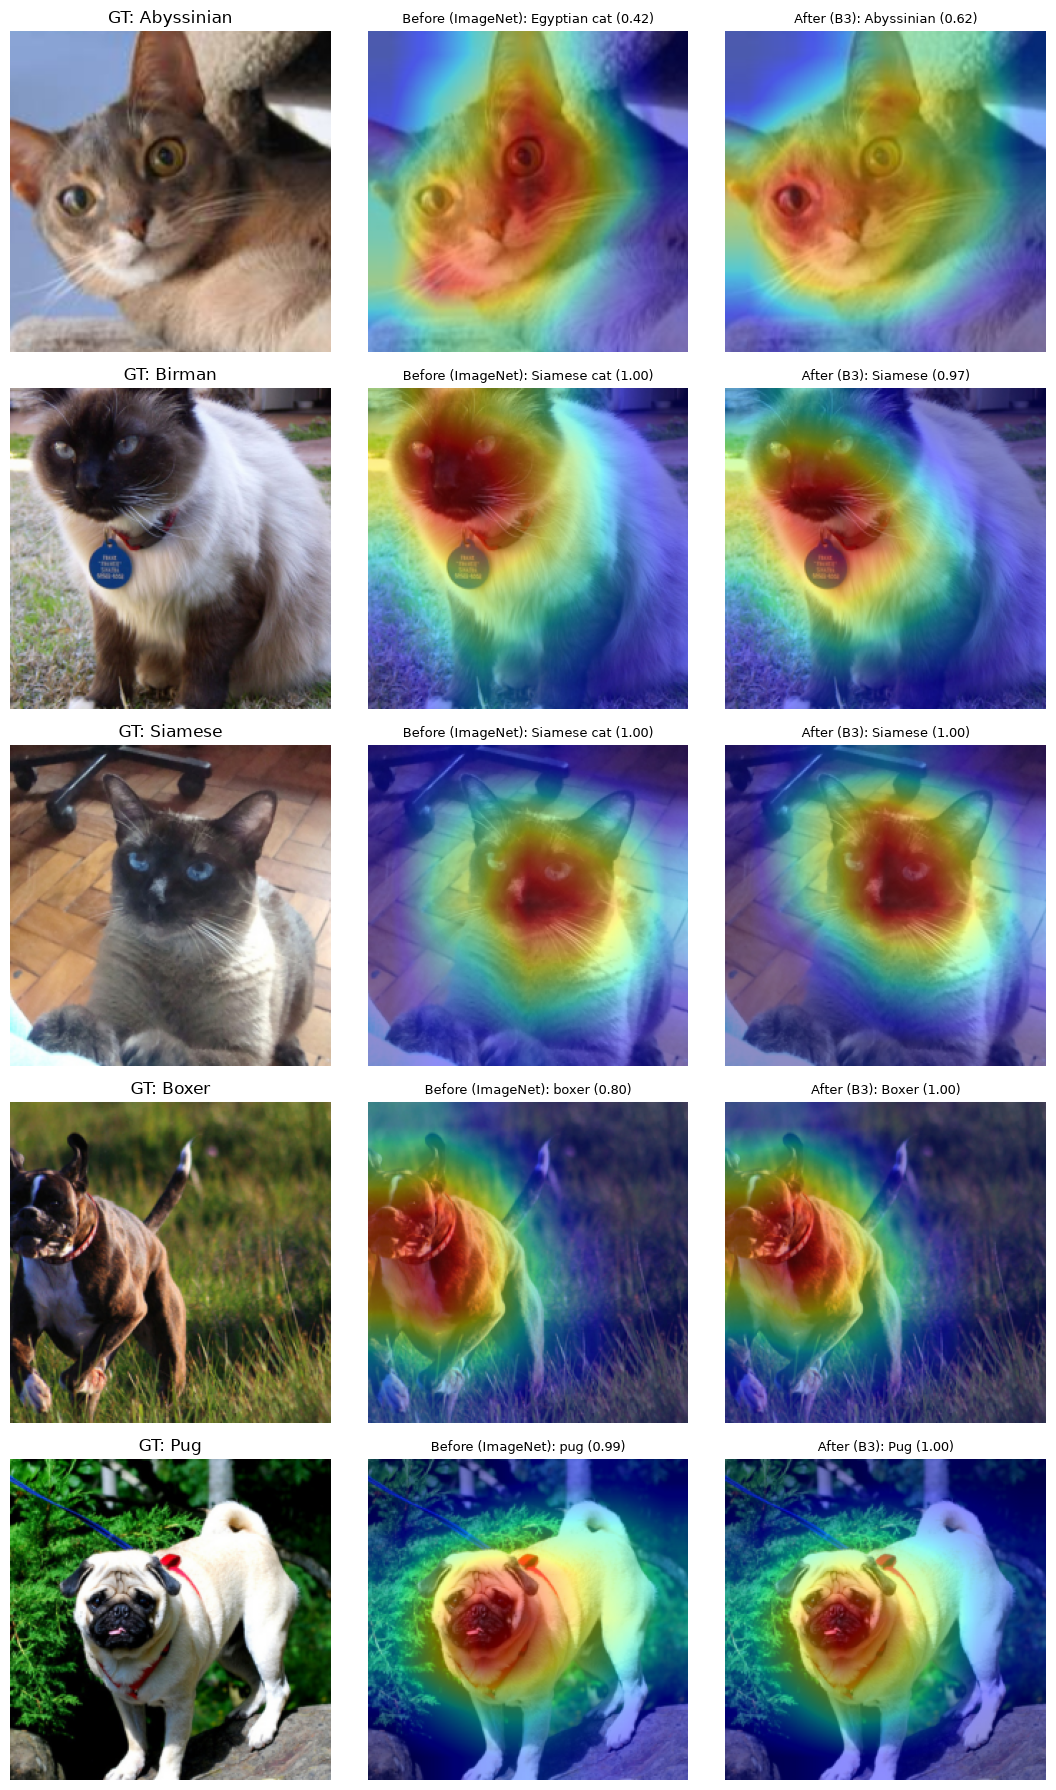

In [22]:
class GradCAM:
    # Grad-CAM (Selvaraju et al., 2017): bobot channel = rata-rata gradien, CAM = ReLU(sum_k w_k * A_k)
    def __init__(self, model, layer):
        self.model = model.eval()
        for p in model.parameters():
            p.requires_grad_(True)
        layer.register_forward_hook(self._hook)

    def _hook(self, module, inp, out):
        self.act = out
        out.register_hook(lambda g: setattr(self, "grad", g))

    def __call__(self, x):
        out = self.model(x)
        cls = out.argmax(1).item()
        self.model.zero_grad()
        out[0, cls].backward()
        w = self.grad.mean((2, 3), keepdim=True)
        cam = F.relu((w * self.act).sum(1, keepdim=True)).detach()
        cam = F.interpolate(cam, size=x.shape[-2:], mode="bilinear", align_corners=False)[0, 0]
        cam = (cam - cam.min()) / (cam.max() - cam.min() + 1e-8)
        return cam.cpu().numpy(), cls, out.softmax(1)[0, cls].item()

imagenet_w = models.ResNet18_Weights.IMAGENET1K_V1
before = models.resnet18(weights=imagenet_w).to(device)
after, _ = build_model("resnet18", "finetune")
after.load_state_dict(torch.load("checkpoints/B3_finetune.pt", map_location=device))
after.to(device)
cam_before, cam_after = GradCAM(before, before.layer4), GradCAM(after, after.layer4)

test_labels = np.array([remap[l] for l in all_labels[test_idx]])
samples = [test_idx[np.where(test_labels == c)[0][0]] for c in range(0, NUM_CLASSES, 2)]

fig, axes = plt.subplots(len(samples), 3, figsize=(11, 3.6 * len(samples)))
for r, i in enumerate(samples):
    x, y = pools["eval"][i]
    img = denorm(x)
    x = x[None].to(device)
    hb, cb, pb = cam_before(x)
    ha, ca, pa = cam_after(x)
    axes[r, 0].imshow(img); axes[r, 0].set_title(f"GT: {CLASSES[y]}")
    axes[r, 1].imshow(img); axes[r, 1].imshow(hb, cmap="jet", alpha=0.45)
    axes[r, 1].set_title(f"Before (ImageNet): {imagenet_w.meta['categories'][cb]} ({pb:.2f})", fontsize=9)
    axes[r, 2].imshow(img); axes[r, 2].imshow(ha, cmap="jet", alpha=0.45)
    axes[r, 2].set_title(f"After (B3): {CLASSES[ca]} ({pa:.2f})", fontsize=9)
for ax in axes.flat:
    ax.axis("off")
plt.tight_layout(); fig.savefig("figures/gradcam_layer4_before_after.png", dpi=150); plt.show()

## 8. Ringkasan Luaran

- `logs/history.csv` — metrik per epoch semua kondisi (train/val loss & acc, waktu).
- `logs/summary.csv`, `logs/metrics.json` — ringkasan per kondisi (trainable params, lr per grup, epoch konvergen, durasi, val acc, test acc, Macro F1, latensi) + konfigurasi & versi library.
- `logs/misclassified_best.csv` — daftar sampel salah prediksi model terbaik.
- `figures/` — kurva loss B1–B3, kurva akurasi B4, confusion matrix, sampel misklasifikasi, Grad-CAM.

Seluruh angka pada laporan (Bagian C) harus diambil dari berkas log di atas.

**Referensi:** He et al. (2016) *Deep Residual Learning for Image Recognition*; Tan & Le (2019) *EfficientNet*;
Howard et al. (2019) *Searching for MobileNetV3*; Selvaraju et al. (2017) *Grad-CAM*; Parkhi et al. (2012) *Cats and Dogs* (Oxford-IIIT Pet);
dokumentasi PyTorch/torchvision.